# A small GWAS on 1000 Genomes, with a South Asian focus

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Gsb057/gwas-1000g-south-asia/blob/main/gwas_1000g_south_asia.ipynb)

**What this does, in one line:** take DNA from 2,504 people (1000 Genomes), clean it,
draw an ancestry map, then scan every DNA position for a link to a trait, once
without and once with ancestry correction.

**To run:** `Runtime → Run all`. About 10-15 minutes. Everything installs itself.

| Step | What happens |
|---|---|
| 0 | Install PLINK, choose settings |
| 1 | Download chromosome 22 + who-is-from-where list |
| 2 | Convert to PLINK format |
| 3 | Quality control: missing data, rare SNPs, Hardy-Weinberg |
| 4 | PCA: the ancestry map |
| 5 | Make a trait (1000 Genomes has none) |
| 6 | GWAS: naive vs. adjusted for ancestry |
| 7 | Manhattan + QQ plots |
| 8 | Summary |

> **Honest note:** 1000 Genomes has no traits or diseases recorded, so the trait here is
> **simulated** with 10 known "true" SNPs. Because we know the truth, we can check
> whether the GWAS finds it.

## 0. Setup
Downloads PLINK 2 (version 2.00a5.12, pinned so results never change), and puts every setting in one place.

In [7]:
import os, tarfile, urllib.request, subprocess
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ---------- settings (change here, rerun everything) ----------
CHROM    = 22       # which chromosome (22 is small: about 200 MB)
GENO     = 0.02     # drop a SNP if missing in more than 2% of people
MIND     = 0.02     # drop a person if missing more than 2% of SNPs
MAF      = 0.01     # drop SNPs where the rarer letter is under 1%
HWE      = 1e-6     # drop SNPs failing Hardy-Weinberg at p < 1e-6
N_PCS    = 10       # number of ancestry PCs to use
SEED     = 42       # fixed seed -> identical results every run
N_CAUSAL = 10       # number of true SNPs in the made-up trait
H2       = 0.30     # share of the trait explained by those SNPs
SHIFT    = {"AFR": 0.6, "EUR": -0.3, "EAS": 0.0, "SAS": 0.2, "AMR": -0.2}  # ancestry effect (the trap)
GWAS_P   = 5e-8     # genome-wide significance

os.makedirs("data", exist_ok=True); os.makedirs("figures", exist_ok=True); os.makedirs("tools", exist_ok=True)

# ---------- install PLINK 2 ----------
PLINK = "tools/bin/plink2"
if not os.path.exists(PLINK):
    url = "https://conda.anaconda.org/bioconda/linux-64/plink2-2.00a5.12-h4ac6f70_0.tar.bz2"
    urllib.request.urlretrieve(url, "tools/plink2.tar.bz2")
    tarfile.open("tools/plink2.tar.bz2").extractall("tools")
    os.chmod(PLINK, 0o755)

def plink(args):
    """Run one PLINK command from Python. Stops with PLINK's message if it fails."""
    r = subprocess.run(f"{PLINK} --threads 2 {args}", shell=True, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-2000:]); raise RuntimeError("PLINK failed")

def count(prefix):
    """How many SNPs and people are in a PLINK file set."""
    snps = sum(1 for l in open(prefix + ".pvar") if not l.startswith("#"))
    ppl  = sum(1 for l in open(prefix + ".psam") if not l.startswith("#"))
    return snps, ppl

print(subprocess.run([PLINK, "--version"], capture_output=True, text=True).stdout)

PLINK v2.00a5.12LM 64-bit Intel (25 Jun 2024)



## 1. Download the data
Two files from the official 1000 Genomes server:
* **the DNA file (VCF):** for every position on chromosome 22, which letters each of the 2,504 people carry.
* **the panel:** which population each person belongs to (GIH, PJL, CEU, YRI, …).

In [8]:
# The same files are kept on three official servers; try each until one works.
MIRRORS = ["https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/release/20130502/",
           "https://ftp-trace.ncbi.nih.gov/1000genomes/ftp/release/20130502/",
           "https://ddbj.nig.ac.jp/public/mirror_database/1000genomes/release/20130502/"]
PANEL = "data/panel.txt"
VCF = f"data/chr{CHROM}.vcf.gz"

def fetch(names, dest):
    """Download the first of `names` that any mirror has. Skips if already downloaded."""
    if os.path.exists(dest):
        print("already have", dest); return
    for base in MIRRORS:
        for name in names:
            try:
                print("trying", base + name)
                urllib.request.urlretrieve(base + name, dest + ".part")
                os.rename(dest + ".part", dest); print("  ok"); return
            except Exception as e:
                print("  not there:", e)
    raise RuntimeError("Could not download " + names[0])

fetch(["integrated_call_samples_v3.20130502.ALL.panel"], PANEL)
fetch([f"ALL.chr{CHROM}.phase3_shapeit2_mvncall_integrated_{v}.20130502.genotypes.vcf.gz" for v in ("v5b", "v5a")], VCF)
print("done")

info = pd.read_csv(PANEL, sep=r"\s+").rename(columns={"sample": "IID", "pop": "POP", "super_pop": "SUPERPOP"})
NAMES = {"GIH": "Gujarati", "PJL": "Punjabi", "BEB": "Bengali", "STU": "Sri Lankan Tamil", "ITU": "Telugu"}
print(info["SUPERPOP"].value_counts().rename("people per continent").to_string())
print()
print(info[info.SUPERPOP == "SAS"]["POP"].map(NAMES).value_counts().rename("South Asian groups").to_string())

already have data/panel.txt
trying https://ftp.1000genomes.ebi.ac.uk/vol1/ftp/release/20130502/ALL.chr22.phase3_shapeit2_mvncall_integrated_v5b.20130502.genotypes.vcf.gz
  ok
done
SUPERPOP
AFR    661
EAS    504
EUR    503
SAS    489
AMR    347

POP
Gujarati            103
Telugu              102
Sri Lankan Tamil    102
Punjabi              96
Bengali              86


## 2. Convert to PLINK format
The VCF is a huge text file. PLINK turns it into a compact binary format. While doing so:
* keep only simple one-letter changes (**SNPs**) with exactly two versions,
* give each SNP a clear name `chromosome:position:letter1:letter2`,
* drop duplicated positions.

In [9]:
plink(f"--vcf {VCF} --snps-only just-acgt --max-alleles 2 "
      f"--set-all-var-ids '@:#:$r:$a' --new-id-max-allele-len 50 --rm-dup exclude-all "
      f"--make-pgen --out data/raw")
print("SNPs: %d   people: %d" % count("data/raw"))

SNPs: 1055454   people: 2504


## 3. Quality control (cleaning)
Four filters, one at a time, so we can see what each removes.

| Filter | Throws out | Why |
|---|---|---|
| `--geno` | SNPs missing in many people | the machine failed to read them, so they're unreliable |
| `--mind` | people missing many SNPs | probably a poor DNA sample |
| `--maf` | very rare SNPs | too few carriers to learn anything (underpowered) |
| `--hwe` | SNPs with impossible-looking genotype counts | usually a genotyping error |

`keep-fewhet`: mixing continents naturally gives *too few* "one of each" people (real biology, not
error), so we only throw out SNPs with *too many*.

             after step    SNPs  people
                  start 1055454    2504
  missing SNPs (--geno) 1055454    2504
missing people (--mind) 1055454    2504
      rare SNPs (--maf)  170949    2504
 Hardy-Weinberg (--hwe)  170052    2504


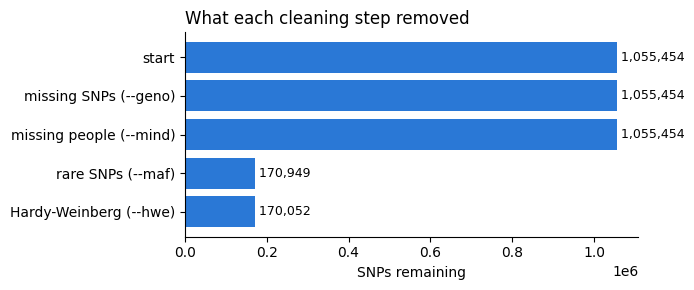

In [10]:
plink(f"--pfile data/raw --geno {GENO} --make-pgen --out data/qc1")              # missing SNPs
plink(f"--pfile data/qc1 --mind {MIND} --make-pgen --out data/qc2")              # missing people
plink(f"--pfile data/qc2 --maf {MAF} --make-pgen --out data/qc3")                # rare SNPs
plink(f"--pfile data/qc3 --hwe {HWE} keep-fewhet --make-pgen --out data/qc")     # Hardy-Weinberg

steps = [("start", "data/raw"), ("missing SNPs (--geno)", "data/qc1"), ("missing people (--mind)", "data/qc2"),
         ("rare SNPs (--maf)", "data/qc3"), ("Hardy-Weinberg (--hwe)", "data/qc")]
qc = pd.DataFrame([(name, *count(p)) for name, p in steps], columns=["after step", "SNPs", "people"])
print(qc.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(qc["after step"][::-1], qc["SNPs"][::-1], color="#2a78d6")
for y, v in enumerate(qc["SNPs"][::-1]): ax.text(v, y, f" {v:,}", va="center", fontsize=9)
ax.set_xlabel("SNPs remaining"); ax.set_title("What each cleaning step removed", loc="left")
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig("figures/qc_steps.png", dpi=150); plt.show()

**Read it:** missing-data filters remove ~nothing, because 1000 Genomes has no missing calls
(gaps were already filled in). The rare-SNP filter removes the most, because most DNA
differences are rare.

## 4. PCA: the ancestry map
1. **LD pruning:** neighbouring SNPs travel together (LD), so they repeat the same information.
   Keep roughly one per neighbourhood, so no single stretch of DNA dominates the map.
2. **PCA:** squeeze each person's thousands of SNPs into a few summary numbers (PC1, PC2, …).
   People with shared ancestry end up close together.

SNPs kept for PCA: 18326


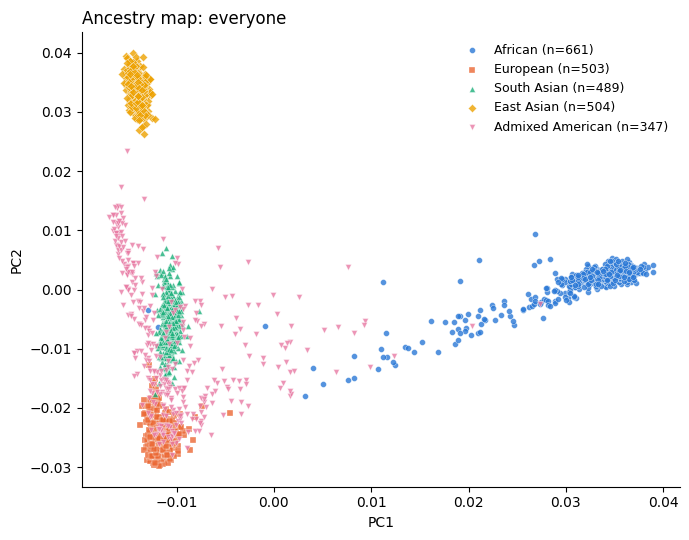

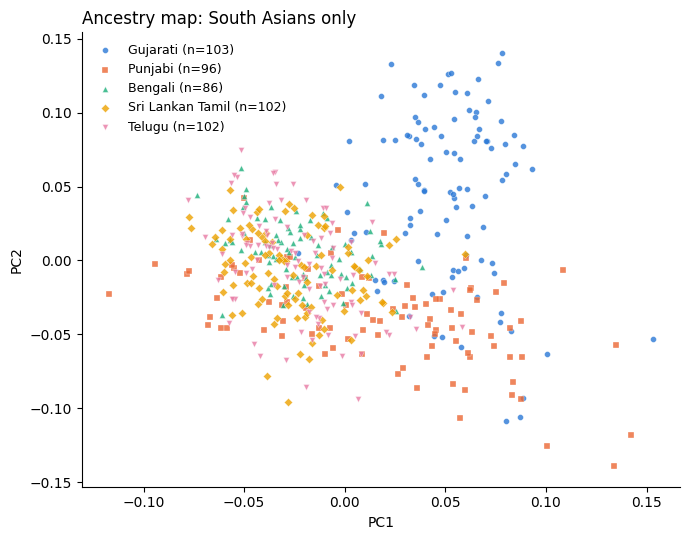

In [11]:
plink(f"--pfile data/qc --indep-pairwise 200 50 0.2 --out data/prune")
print("SNPs kept for PCA:", sum(1 for _ in open("data/prune.prune.in")))
plink(f"--pfile data/qc --extract data/prune.prune.in --pca {N_PCS} --out data/pca_all")

sas_ids = info.loc[info.SUPERPOP == "SAS", ["IID"]]
sas_ids.to_csv("data/sas.ids", index=False, header=False)
plink(f"--pfile data/qc --keep data/sas.ids --extract data/prune.prune.in --maf {MAF} --pca {N_PCS} --out data/pca_sas")

def read_pcs(prefix):
    pcs = pd.read_csv(prefix + ".eigenvec", sep=r"\s+").rename(columns={"#IID": "IID"})
    return pcs.merge(info, on="IID")

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
MARKS  = ["o", "s", "^", "D", "v"]
def pca_plot(df, col, groups, title, path):
    fig, ax = plt.subplots(figsize=(7, 5.5))
    for (g, label), c, m in zip(groups, COLORS, MARKS):
        d = df[df[col] == g]
        ax.scatter(d.PC1, d.PC2, s=18, c=c, marker=m, alpha=.8, edgecolors="white", linewidths=.3, label=f"{label} (n={len(d)})")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(title, loc="left")
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.legend(frameon=False, fontsize=9); plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

pcs_all = read_pcs("data/pca_all")
pca_plot(pcs_all, "SUPERPOP", [("AFR", "African"), ("EUR", "European"), ("SAS", "South Asian"), ("EAS", "East Asian"), ("AMR", "Admixed American")],
         "Ancestry map: everyone", "figures/pca_all.png")
pca_plot(read_pcs("data/pca_sas"), "POP", list(NAMES.items()),
         "Ancestry map: South Asians only", "figures/pca_south_asian.png")

**Read it:** in the first map, Africans sit far from everyone (the oldest split in human
history), and South Asians sit between Europeans and East Asians, closer to Europeans.
In the second map, the five South Asian groups spread out from north (Punjabi, Gujarati)
to south (Tamil, Telugu).

## 5. Make a trait
1000 Genomes has no traits, so we build one where we know the answer:

**trait = 10 true SNPs (30% of the variation) + an ancestry shift (the trap) + random noise**

The ancestry shift copies real life: a trait can differ between populations for
non-genetic reasons (diet, environment). That's what creates fake hits later.

In [12]:
rng = np.random.default_rng(SEED)
plink("--pfile data/qc --freq --out data/qc")
af = pd.read_csv("data/qc.afreq", sep="\t").rename(columns={"#CHROM": "CHROM"})
af["MAF"] = np.minimum(af.ALT_FREQS, 1 - af.ALT_FREQS)
af["POS"] = af.ID.str.split(":").str[1].astype(int)

# pick N_CAUSAL common SNPs, at least 2 million letters apart (so each is its own peak)
causal = []
for _, r in af[af.MAF >= 0.05].sample(frac=1, random_state=SEED).iterrows():
    if all(abs(r.POS - c.POS) > 2_000_000 for c in causal): causal.append(r)
    if len(causal) == N_CAUSAL: break
causal = pd.DataFrame(causal)[["ID", "POS", "MAF"]].reset_index(drop=True)
causal.ID.to_csv("data/causal.txt", index=False, header=False)

# get those SNPs as 0/1/2 counts for every person
plink("--pfile data/qc --extract data/causal.txt --export A --out data/causal")
raw = pd.read_csv("data/causal.raw", sep=r"\s+")
G = raw.iloc[:, 6:]; G.columns = [c.rsplit("_", 1)[0] for c in G.columns]
G = G[causal.ID].fillna(G.mean())
Z = (G - G.mean()) / G.std()                      # put every SNP on the same scale

genetic = Z.values @ rng.normal(0, 1, len(causal))   # each true SNP gets a random effect
genetic = genetic / genetic.std() * np.sqrt(H2)   # genes explain H2 of the trait
noise   = rng.normal(0, np.sqrt(1 - H2), len(raw))
superpop = raw.IID.map(info.set_index("IID").SUPERPOP)
trap    = superpop.map(SHIFT).fillna(0).values    # the ancestry shift

pd.DataFrame({"#IID": raw.IID, "TRAIT": genetic + trap + noise}).to_csv("data/trait.tsv", sep="\t", index=False)
print("True SNPs:", ", ".join(causal.ID))
trait = pd.Series(genetic + trap + noise)
print(trait.groupby(superpop.values).mean().round(2).rename("average trait by continent").to_string())

True SNPs: 22:39079413:A:G, 22:47113978:C:A, 22:33729867:G:A, 22:49134056:G:A, 22:43470219:G:A, 22:19147099:C:T, 22:21148621:C:T, 22:28034300:C:G, 22:25456109:G:A, 22:41112204:C:A
AFR    0.74
AMR   -0.36
EAS    0.31
EUR   -0.63
SAS   -0.03


## 6. The GWAS
At every SNP, fit a straight line: **trait = a + b × (0, 1 or 2 copies)**. The slope **b** is the
effect size; the p-value asks whether b is really different from 0.

We run it **twice**:
* **naive:** trait ~ SNP. Ancestry is ignored.
* **adjusted:** trait ~ SNP + PC1…PC10. Ancestry is held constant (PCs as covariates).

In [13]:
plink("--pfile data/qc --pheno data/trait.tsv --pheno-name TRAIT --glm allow-no-covars --out data/naive")
plink(f"--pfile data/qc --pheno data/trait.tsv --pheno-name TRAIT --covar data/pca_all.eigenvec "
      f"--covar-name PC1-PC{N_PCS} --covar-variance-standardize --glm hide-covar --out data/adjusted")

def load(name):
    d = pd.read_csv(f"data/{name}.TRAIT.glm.linear", sep="\t").rename(columns={"#CHROM": "CHROM"})
    d = d[d.P.notna()].copy(); d["LOGP"] = -np.log10(d.P.clip(lower=1e-300)); return d
res = {"naive": load("naive"), "adjusted": load("adjusted")}
for k, d in res.items():
    print(f"{k:9s}: {len(d):,} SNPs tested, {(d.P < GWAS_P).sum():,} below 5e-8")

naive    : 170,052 SNPs tested, 63,484 below 5e-8
adjusted : 170,052 SNPs tested, 367 below 5e-8


## 7. Manhattan and QQ plots
* **Manhattan plot:** each dot is a SNP; height = how strong the evidence is (−log10 p, so
  higher = smaller p). Dashed line = 5×10⁻⁸. Black circles = the 10 true SNPs we planted.
* **QQ plot:** compares our p-values with what pure luck would give. On the diagonal = no
  problem. Whole curve lifted = something fake is going on (here: ancestry).
* **λ (lambda):** a single number for "how lifted". About 1 = good.

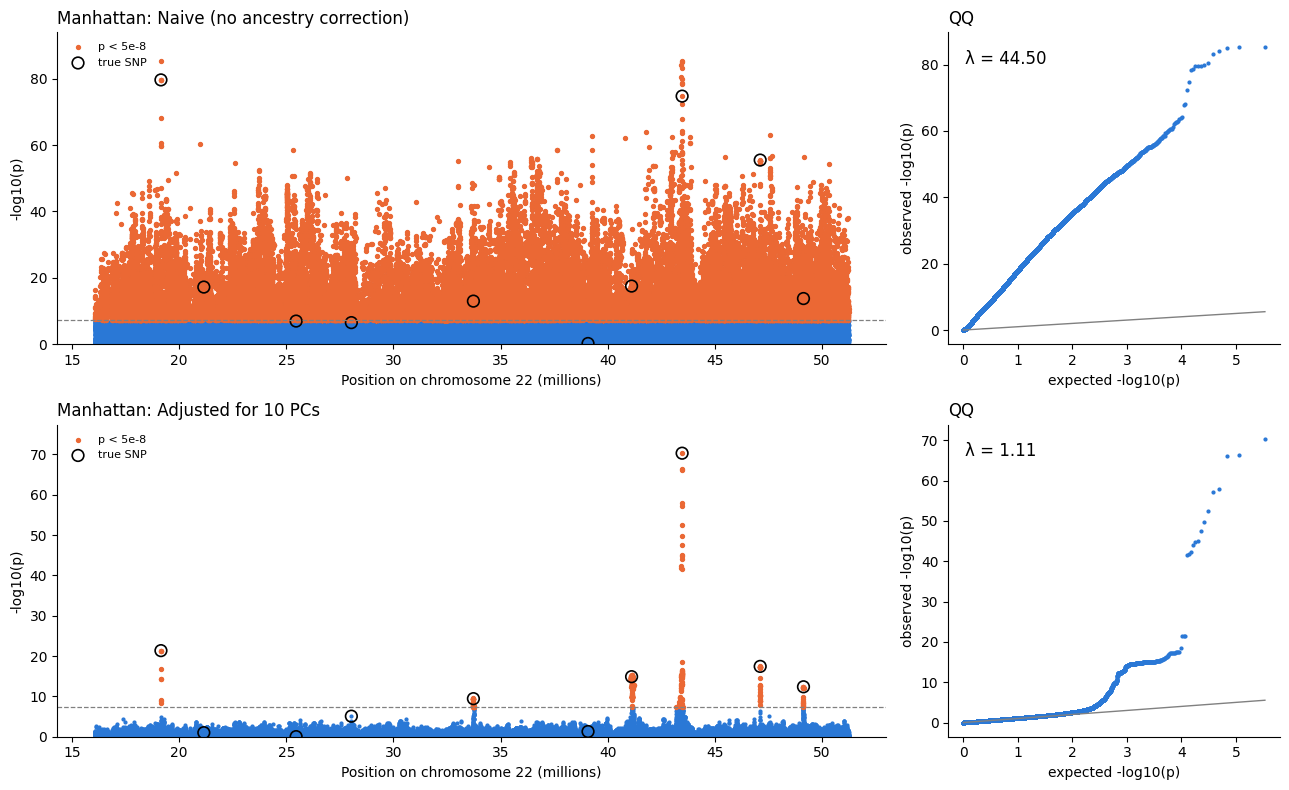

analysis  lambda  hits (p<5e-8) true SNPs found
   naive   44.50          63484            7/10
adjusted    1.11            367            6/10


In [14]:
def lam(p): return np.median(stats.chi2.isf(p, 1)) / stats.chi2.ppf(0.5, 1)

fig, axes = plt.subplots(2, 2, figsize=(13, 8), gridspec_kw={"width_ratios": [2.5, 1]})
titles = {"naive": "Naive (no ancestry correction)", "adjusted": "Adjusted for 10 PCs"}
summary = []
for row, (k, d) in enumerate(res.items()):
    ax = axes[row, 0]
    ax.scatter(d.POS / 1e6, d.LOGP, s=4, c="#2a78d6", rasterized=True)
    hit = d[d.P < GWAS_P]; ax.scatter(hit.POS / 1e6, hit.LOGP, s=8, c="#eb6834", label="p < 5e-8")
    tru = d[d.ID.isin(causal.ID)]
    ax.scatter(tru.POS / 1e6, tru.LOGP, s=70, facecolors="none", edgecolors="black", linewidths=1.2, label="true SNP")
    ax.axhline(-np.log10(GWAS_P), ls="--", c="grey", lw=.9)
    ax.set_ylim(0, d.LOGP.max() * 1.1); ax.set_xlabel(f"Position on chromosome {CHROM} (millions)"); ax.set_ylabel("-log10(p)")
    ax.set_title(f"Manhattan: {titles[k]}", loc="left"); ax.legend(frameon=False, fontsize=8, loc="upper left")

    ax = axes[row, 1]
    p = np.sort(d.P.values); n = len(p); exp = -np.log10((np.arange(1, n + 1) - .5) / n)
    ax.scatter(exp, -np.log10(p), s=4, c="#2a78d6", rasterized=True)
    ax.plot([0, exp.max()], [0, exp.max()], c="grey", lw=1)
    L = lam(d.P.values); ax.text(.05, .9, f"λ = {L:.2f}", transform=ax.transAxes, fontsize=12)
    ax.set_xlabel("expected -log10(p)"); ax.set_ylabel("observed -log10(p)"); ax.set_title("QQ", loc="left")

    summary.append({"analysis": k, "lambda": round(L, 2), "hits (p<5e-8)": len(hit),
                    "true SNPs found": f"{d[d.P < GWAS_P].ID.isin(causal.ID).sum()}/{len(causal)}"})
for a in axes.flat:
    for s in ("top", "right"): a.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig("figures/manhattan_qq.png", dpi=150); plt.show()
summary = pd.DataFrame(summary); print(summary.to_string(index=False))

## 8. Summary
Printed in plain words, ready to paste into the README.

In [15]:
n, a = summary.iloc[0], summary.iloc[1]
s0, p0 = count("data/raw"); s1, p1 = count("data/qc")
print(f"""On 1000 Genomes chromosome {CHROM} ({p1:,} people), quality control kept {s1:,} of {s0:,} SNPs.
PCA separated the continents, and South Asians fell between Europeans and East Asians.
With a simulated trait containing {len(causal)} true SNPs plus an ancestry effect:
  - without ancestry correction: lambda = {n['lambda']}, {n['hits (p<5e-8)']} SNPs below 5e-8
  - with 10 PCs as covariates:   lambda = {a['lambda']}, {a['hits (p<5e-8)']} SNPs below 5e-8, true SNPs found: {a['true SNPs found']}""")

On 1000 Genomes chromosome 22 (2,504 people), quality control kept 170,052 of 1,055,454 SNPs.
PCA separated the continents, and South Asians fell between Europeans and East Asians.
With a simulated trait containing 10 true SNPs plus an ancestry effect:
  - without ancestry correction: lambda = 44.5, 63484 SNPs below 5e-8
  - with 10 PCs as covariates:   lambda = 1.11, 367 SNPs below 5e-8, true SNPs found: 6/10
